# Card 08 – People & costs
**Question:** can we manage staff and costs with this data?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = pd.read_pickle('../clean/cottonil_clean.pkl')

# colours: blue = main, grey = context, orange = the ONE thing each chart wants you to look at
BLUE, ORANGE, AQUA, GREY, LIGHT, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b5b4ae', '#b9d3f2', '#52514e'
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'figure.dpi': 110})


def style(ax, title, ylabel=None):
    """Title = the insight, light grid, no box."""
    ax.set_title(title, loc='left', pad=12)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#ecebe7'); ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)


def save(fig, name):
    fig.savefig(f'../outputs/charts/{name}.png', dpi=150, bbox_inches='tight')


def full_years(d, col='fy'):
    """Complete fiscal years only: FY2019 → FY2026 (Oct–Sep)."""
    return d[(d[col] >= 2019) & (d[col] <= 2026)]


M = lambda x: f'{x / 1e6:,.1f}M'

In [2]:
em = files['employees']
roles = em.pivot_table(index='branch_id', columns='position_en', values='employee_id', aggfunc='count', fill_value=0)
print('employees:', len(em), '| per branch:', em.groupby('branch_id').size().unique().tolist())
print('branches with no store manager:', (roles['Store Manager'] == 0).sum(), '| with no cashier:', (roles['Cashier'] == 0).sum(),
      '| with both:', ((roles['Store Manager'] > 0) & (roles['Cashier'] > 0)).sum())
print('area managers:', (em.position_en == 'Area Manager').sum(), 'for 80 branches')
print('first 12 employees (role repeats every 6):', em.position_en.head(12).tolist())
em.groupby('position_en').salary_base_EGP_2026.agg(['count', 'mean', 'min', 'max']).round(0).sort_values('mean', ascending=False)

employees: 640 | per branch: [8]
branches with no store manager: 40 | with no cashier: 40 | with both: 0
area managers: 106 for 80 branches
first 12 employees (role repeats every 6): ['Cashier', 'Sales Associate', 'Sales Associate', 'Store Manager', 'Inventory Clerk', 'Area Manager', 'Cashier', 'Sales Associate', 'Sales Associate', 'Store Manager', 'Inventory Clerk', 'Area Manager']


,count,mean,min,max
position_en,,,,
Store Manager,107,12487.0,5400,18400
Cashier,107,11959.0,5300,18400
Sales Associate,214,11899.0,5300,18300
Area Manager,106,11691.0,5300,18400
Inventory Clerk,106,11539.0,5200,18000


payroll FY2026: 5.6M EGP vs base salaries on the list: 91.5M EGP/year


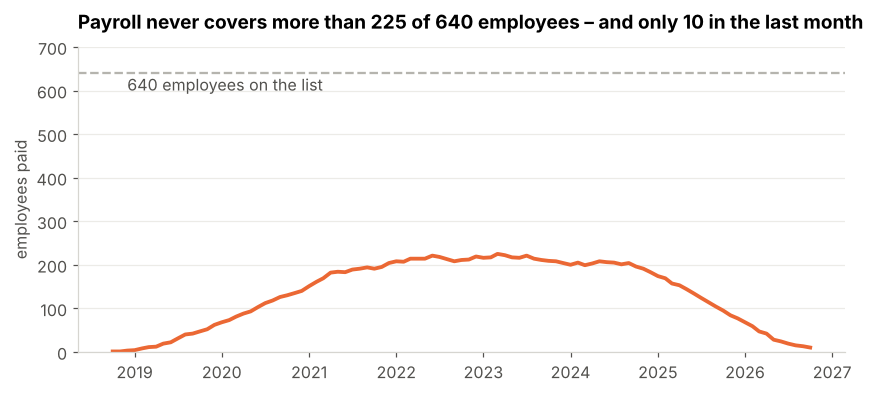

In [3]:
pa = files['payroll']
paid = pa.groupby('pay_month').employee_id.nunique()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(paid.index, paid, color=ORANGE, lw=2.5)
ax.axhline(len(em), color=GREY, ls='--'); ax.text(paid.index[2], len(em) - 40, f'{len(em)} employees on the list', color=INK)
ax.set_ylim(0, 700)
style(ax, f'Payroll never covers more than {paid.max()} of {len(em)} employees – and only {paid.iloc[-1]} in the last month', 'employees paid')
save(fig, 'c08_payroll_coverage')
print(f'payroll FY2026: {M(full_years(pa).groupby("fy").net_paid_EGP.sum().loc[2026])} EGP vs base salaries on the list: {M(em.salary_base_EGP_2026.sum() * 12)} EGP/year')

In [4]:
ox, so = files['opex'], full_years(files['orders'])
y = full_years(ox).groupby('fy').amount_EGP.sum() / so.groupby('fy').net_before_tax_EGP.sum() * 100
print('operating expenses as % of sales:', y.round(1).to_dict())
rent = ox[ox.expense_category == 'Rent'].groupby('branch_or_department_id').month.nunique()
print(f'rent recorded per location: {rent.mean():.0f} of {ox.month.nunique()} months on average ({rent.min()}–{rent.max()})')
print(f'marketing in the expense ledger: {M(ox[ox.expense_category == "Marketing"].amount_EGP.sum())} vs campaign table: {M(files["campaigns"].spend_EGP.sum())}')
(ox.groupby('expense_category').amount_EGP.sum() / ox.amount_EGP.sum() * 100).round(1).sort_values(ascending=False).to_frame('% of expenses')

operating expenses as % of sales: {2019: 30.9, 2020: 28.3, 2021: 24.6, 2022: 22.1, 2023: 19.1, 2024: 16.3, 2025: 14.0, 2026: 13.2}
rent recorded per location: 39 of 97 months on average (25–64)
marketing in the expense ledger: 11.8M vs campaign table: 219.5M


,% of expenses
expense_category,
Rent,16.9
Utilities,16.9
Marketing,8.7
Travel,8.5
Logistics,8.4
Insurance,8.2
Maintenance,8.2
General administration,8.1
IT & software,8.0


### Takeaway (card 08)
- Roles are assigned in rotation: **40 branches have no store manager and 40 have no cashier**, 106 area managers for 80 branches, and salary does not depend on the role.
- Payroll is incomplete (max 225 of 640 people in a month, 10 in the last one): FY2026 payroll 5.6M vs ~91M of base salaries on the list.
- Expenses: 10 categories with near-equal shares; rent appears in ~39 of 97 months per branch; marketing in the ledger ≠ campaign spend.
- So: **no workforce-productivity app** can be honest on this data. What we deliver instead is the list of HR / finance data to fix (Data Trust Center).